# g-distance: accommodation and excess flexibility

*The vignette `vignette("gdistance")` of the R package clobe, ported to `psp.clobe`.*

A common way to evaluate a model is to fit it to the average result and see how close it gets. But people differ, and a model of human behaviour should be able to do what each of them does, without doing much that none of them do. g-distance (Dome & Wills, 2025) measures exactly that. This notebook defines it step by step, works through an example by hand, and shows how to read the result.

In [1]:
import sys

import math
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

from psp import clobe

sys.path.insert(0, "..")  # for notebooks/figure_style.py
from figure_style import aqua, blue, figures, ink, light, muted, orange, reference, titled

show = figures("clobe-gdistance")


## Three sets of patterns

Everything is expressed in terms of ordinal patterns (inequality matrices; see [inequality-matrices.ipynb](inequality-matrices.ipynb)). g-distance uses three sets of them (Dome & Wills, 2025, Figure 3):

- $H$, the patterns **h**umans have been observed to show under some defined conditions, such as one experiment.
- $M$, the patterns the **m**odel can produce under those conditions, found by parameter space partitioning.
- $U$, the **u**niversal set of every conceivable pattern: observed or not, producible by the model or not (see [universal-set.ipynb](universal-set.ipynb)).

$H$ and $M$ are both parts of $U$, and a prime marks the rest of $U$: $H'$ is every pattern nobody showed, $M'$ every pattern the model cannot produce. Each set counts a pattern once, however often it occurs.

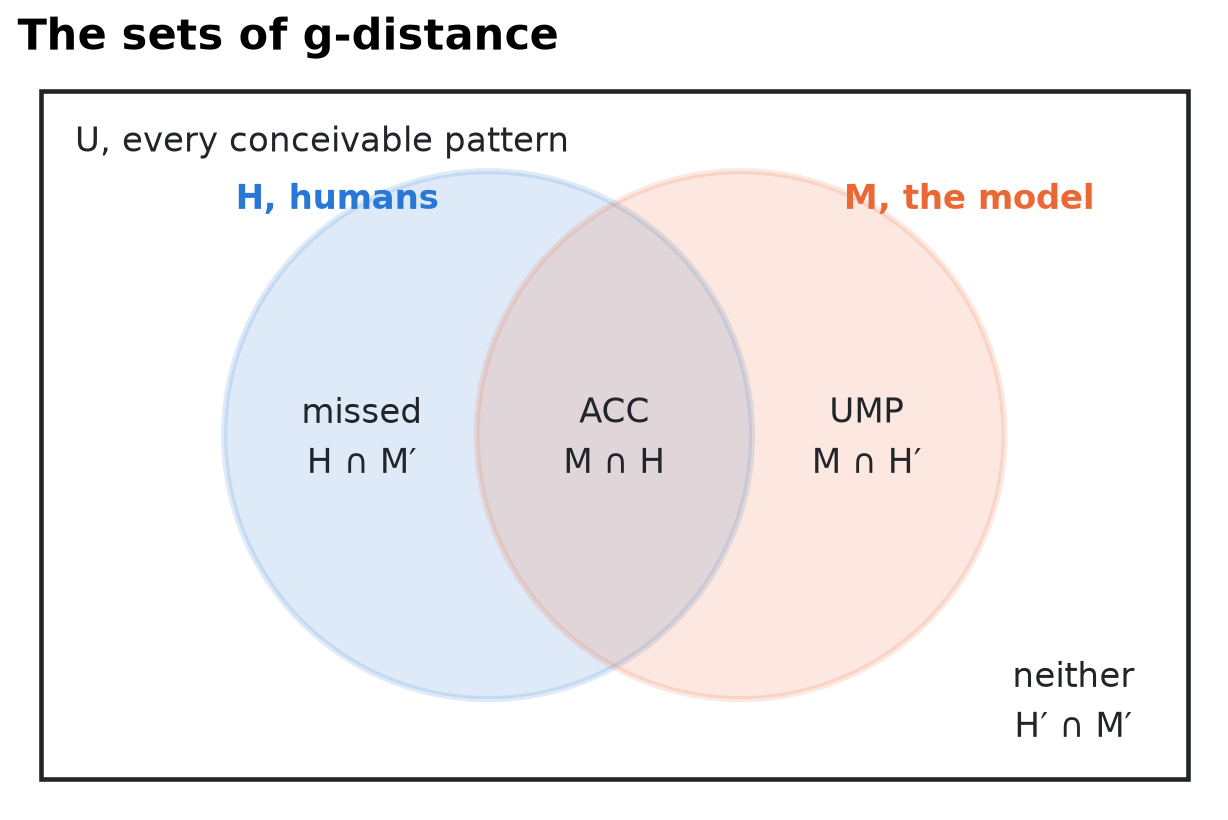

In [2]:
from matplotlib.patches import Circle, Rectangle

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.add_patch(Rectangle((0, 0), 10, 6, facecolor="white", edgecolor=ink, linewidth=1.5))
ax.add_patch(Circle((3.9, 3), 2.3, facecolor=blue, alpha=0.15, edgecolor=blue, linewidth=2))
ax.add_patch(Circle((6.1, 3), 2.3, facecolor=orange, alpha=0.15, edgecolor=orange, linewidth=2))
ax.text(0.3, 5.55, "U, every conceivable pattern", color=ink, fontsize=11, va="center")
ax.text(1.7, 5.05, "H, humans", color=blue, fontsize=11, va="center", fontweight="bold")
ax.text(7.0, 5.05, "M, the model", color=orange, fontsize=11, va="center", fontweight="bold")
for x, y, text in [(2.8, 3, "missed\nH ∩ M′"), (5, 3, "ACC\nM ∩ H"), (7.2, 3, "UMP\nM ∩ H′"),
                   (9, 0.7, "neither\nH′ ∩ M′")]:
    ax.text(x, y, text, color=ink, fontsize=11, ha="center", va="center", linespacing=1.5)
ax.set(xlim=(-0.2, 10.2), ylim=(-0.2, 6.2), aspect="equal")
ax.axis("off")
ax.set_title("The sets of g-distance")
show(fig, "sets")

A pattern the model produces that people showed is an **accommodation** (ACC, $M \cap H$). A pattern the model says should be observable, but that nobody has shown, is an **unobserved model pattern** (UMP, $M \cap H'$); if it is observed later, it becomes an accommodation. A model can be inadequate in two ways: through a deficit of accommodation, missing patterns people show ($H \cap M'$), or through an excess of UMPs, a lack of specificity. A model that can produce every logically possible result never fails to accommodate, and explains nothing. With perfect information, a perfect theory accommodates everything in $H$ and produces no UMPs: both $H \cap M'$ and $M \cap H'$ are empty.

## Accommodation: alpha

**Accommodation** is the share of the human patterns the model produces:

$$
\alpha = \frac{|M \cap H|}{|H|} \qquad \text{(Equation 1)}.
$$

It runs from 0 (the model produces none of the patterns people showed) to 1 (it produces them all).

### Weighting by how many people show a pattern

In their application, Dome and Wills (2025) computed g-distance for each participant's trial order. Each trial order has a single human pattern, so for each participant $\alpha$ is either 1 or 0: the model produces that person's pattern or it does not. The reported $\alpha$ is the average over participants, which weights every pattern by how many people show it: if one pattern is shown by 100 people and another by 10, the model's success on the first counts ten times as much.

`gdistance()` gives this weighting directly through `frequencies`, the proportion $f_h$ of people with each pattern:

$$
\alpha = \sum_{h \in H} f_h \times
\begin{cases} 1 & \text{if } h \in M \\ 0 & \text{otherwise.} \end{cases}
$$

For a model whose patterns do not depend on the trial order, this is the average of the participants' $\alpha$; with the same frequency for every pattern, it is Equation 1.

## Excess flexibility: beta

**Excess flexibility**, the breadth of UMPs, is the number of patterns the model produces that nobody showed, as a proportion of all the patterns nobody showed:

$$
\beta = \frac{|M \cap H'|}{|H'|} = \frac{|M \setminus H|}{|U| - |H|} \qquad \text{(Equation 2)}.
$$

It runs from 0 (the model produces nothing beyond what was observed) to 1 (it produces every unobserved pattern). `gdistance()` computes it from the pooled set of human patterns, $H$. In the per-trial-order calculation of the paper, each participant's $H$ holds that participant's single pattern, and $\beta$ is averaged over participants instead.

## Combining them: g-distance

With complete information, a perfect model has $\alpha = 1$ and $\beta = 0$: the **PAS** point, for Perfect Accommodation and Specificity, specificity being $1 - \beta$. A model's inadequacy is its distance from that point in the two-dimensional space of $1 - \alpha$ and $\beta$:

$$
g = \sqrt{\frac{(1 - \alpha)^2 + \beta^2}{2}} \qquad \text{(Equation 3)},
$$

where the division by 2 keeps $g$ between 0 and 1. With complete information, $g$ is the distance of the model from the ground truth of the observations, hence **g-distance**, ground truth distance. Lower is better.

Equation 3 weighs accommodation and specificity equally, a default rather than a strong theoretical commitment. With a weight $w$ between 0 and 1,

$$
g = \sqrt{w (1 - \alpha)^2 + (1 - w) \beta^2} \qquad \text{(Equation 4)}.
$$

A larger $w$ penalises missed human behaviour more, a smaller $w$ penalises UMPs more, and "model A is more adequate than model B" ($g_A < g_B$) can be stated for a range of beliefs about $w$, such as $1 > w > 0.25$.

## A worked example

Three stimuli, four participants. Two produce the same pattern (A), and one each produces B and C. The model produces A and B, and two patterns nobody showed (D and E).

In [3]:
thresholds = (0.1, -0.1)
people = torch.tensor([[0.9, 0.5, 0.1],   # A: 0 > 1 > 2
                       [0.8, 0.5, 0.2],   # A again
                       [0.1, 0.5, 0.9],   # B: 0 < 1 < 2
                       [0.5, 0.5, 0.5]])  # C: all about the same
model = torch.tensor([[0.9, 0.5, 0.1],    # A
                      [0.1, 0.5, 0.9],    # B
                      [0.9, 0.9, 0.1],    # D: 0 = 1 > 2
                      [0.1, 0.9, 0.9]])   # E: 0 < 1 = 2

human = clobe.patterns(people, thresholds)
model = clobe.patterns(model, thresholds)
human.frequencies

tensor([0.5000, 0.2500, 0.2500], dtype=torch.float64)

By hand:

- $\alpha$: A (half of the people) and B (a quarter) are accommodated, C is not: $\alpha = 0.5 + 0.25 = 0.75$.
- $\beta$: there are 19 possible patterns of 3 stimuli (`semiorders(3)`), and people showed 3 of them, leaving 16. The model produces 2 of those 16 (D and E): $\beta = 2 / 16 = 0.125$.
- $g = \sqrt{0.5 \times 0.25^2 + 0.5 \times 0.125^2} \approx 0.198$.

And with `psp.clobe`:

In [4]:
clobe.gdistance(human.inequality_matrices, model.inequality_matrices,
                universal=clobe.semiorders(3), weight=0.5, frequencies=human.frequencies)

GDistanceResult(gdistance=0.19764235376052372, alpha=0.75, beta=0.125, accommodation=tensor([0, 1]))

`accommodation` lists which human patterns (by their index in `human.inequality_matrices`, from 0) the model produces. The R package returns `alpha`, `beta` and `accommodation` only with `xtdo = TRUE`; here they are always there, and `float(result)` is the g-distance.

## Comparing models

Here are three models of the four-stimulus experiment from [getting-started.ipynb](getting-started.ipynb), where 40 simulated participants respond to four stimuli whose feature $x$ is $-1.5, -0.5, 0.5$ and $1.5$:

- The **linear** model, $p_i = \sigma(b \, x_i)$ with $\sigma(z) = 1/(1 + e^{-z})$, makes the response rate change in one direction across the stimuli: rising for a positive slope $b$, falling for a negative one, flat near zero. It can only produce monotonic patterns. The participants were simulated from this model plus noise, so their patterns include the ones it produces and others that the noise adds.
- The **quadratic** model, $p_i = \sigma(b \, x_i + c \, x_i^2)$, adds a curvature $c$, so it can also produce U-shapes and inverted U-shapes. It contains the linear model ($c = 0$), so it produces every pattern the linear model does.
- The **random** model draws each probability independently and uniformly between 0 and 1, 2,000 times. It is not a theory of anything: it stands for a model that can produce almost any pattern, close to the degenerate model of the next section.

Each is evaluated on its parameters (a grid from $-3$ to $3$ in steps of $0.1$ for $b$ and $c$), and its patterns compared with the people's.

In [5]:
g = torch.Generator().manual_seed(2025)
x = torch.tensor([-1.5, -0.5, 0.5, 1.5], dtype=torch.float64)
slopes = 0.5 + torch.randn(40, generator=g, dtype=torch.float64)
p = torch.sigmoid(slopes[:, None] * x + 0.3 * torch.randn(40, 4, generator=g, dtype=torch.float64))
human = clobe.patterns(torch.binomial(torch.full_like(p, 20.0), p, generator=g) / 20, thresholds)

grid = torch.arange(-30, 31, dtype=torch.float64) / 10
b, c = (t.reshape(-1, 1) for t in torch.meshgrid(grid, grid, indexing="ij"))
models = {
    "linear": torch.sigmoid(grid[:, None] * x),
    "quadratic": torch.sigmoid(b * x + c * x**2),
    "random": torch.rand(2000, 4, generator=g, dtype=torch.float64),
}


def score(results):
    out = clobe.gdistance(human.inequality_matrices,
                          clobe.patterns(results, thresholds).inequality_matrices,
                          universal=clobe.semiorders(4), weight=0.5, frequencies=human.frequencies)
    return {"alpha": out.alpha, "beta": out.beta, "g": out.gdistance}


scores = pd.DataFrame({name: score(results) for name, results in models.items()}).T
scores.round(3)

,alpha,beta,g
linear,0.225,0.037,0.549
quadratic,0.575,0.385,0.406
random,0.975,0.839,0.593


### Reading a model off the α-β plane

Dome and Wills (2025, Figure 4) plot a model by its excess flexibility $\beta$ against its accommodation $\alpha$, beside three reference models. Assume we know everything there is to know about the behaviour, and are testing theories of it:

- **PAS** (Perfect Accommodation and Specificity), at $\alpha = 1$, $\beta = 0$: the ideal model, producing every pattern people showed and nothing else; $g = 0$.
- **anti-PAS**, at $\alpha = 0$, $\beta = 1$: the worst possible model, accommodating nothing that is observed and producing everything that is not; $g = 1$.
- **degenerate**, at $\alpha = 1$, $\beta = 1$: accommodates everything that is observed, but also produces everything that is not. It assumes that everything that could in theory be observed is in fact observed, which makes it indistinguishable from an account that human behaviour is unlawful. $g = \sqrt{1 - w}$, 0.71 for $w = 0.5$.

Any model with a g-distance of $\sqrt{1 - w}$ or more is no more adequate than the degenerate model: it has **degenerate-level** adequacy, even if it is not degenerate itself. The line of the degenerate level joins every point as far from the ideal as the degenerate model, $w(1 - \alpha)^2 + (1 - w)\beta^2 = 1 - w$, which for $w = 0.5$ is $\alpha = 1 - \sqrt{1 - \beta^2}$. Being above it is a minimum threshold for model adequacy; below $\sqrt{1 - w}$, g-distance is largely comparative. The line is not straight: a model with low accommodation (below about 0.35) can add UMPs faster than it adds accommodations without falling to the degenerate level, while for a model with high accommodation the opposite holds, so keeping a lid on new UMPs matters more as a model gets better at accommodating (Dome & Wills, 2025, footnote 2). The three models above are shown with their g-distance in brackets.

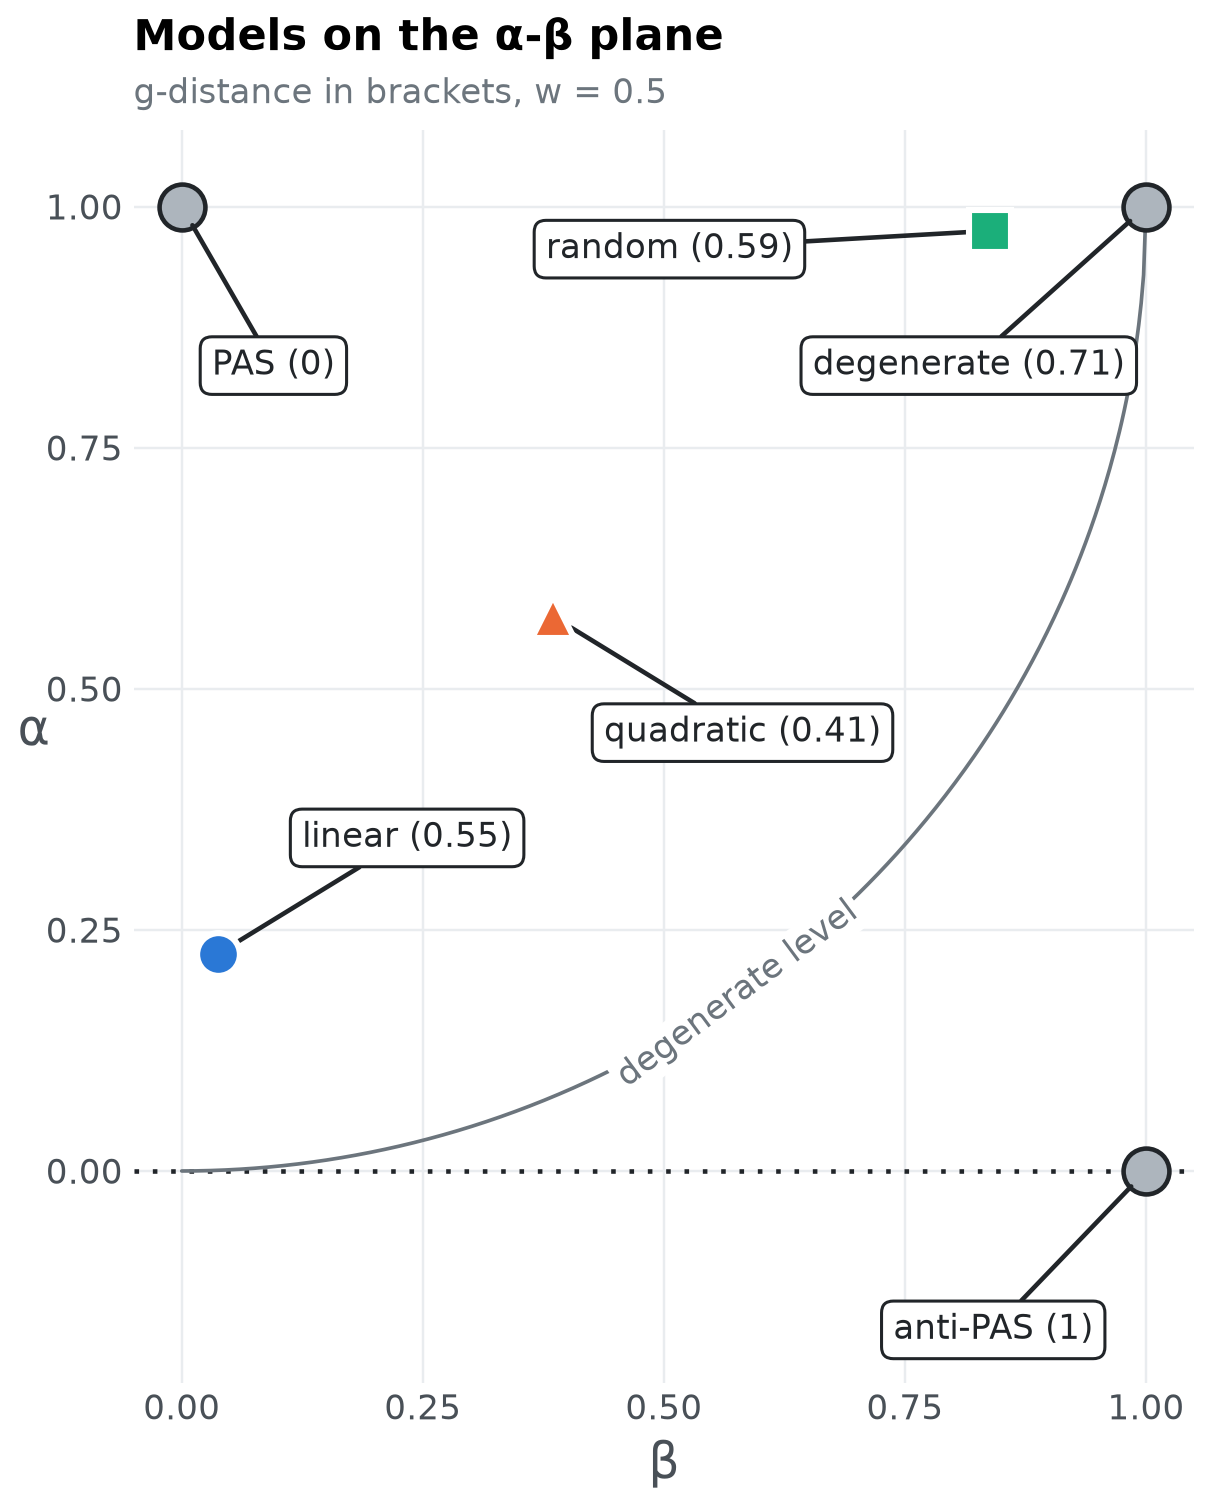

In [6]:
colours = {"linear": blue, "quadratic": orange, "random": aqua}
markers = {"linear": "o", "quadratic": "^", "random": "s"}  # a second cue besides colour,
styles = {"linear": "-", "quadratic": "--", "random": "-."}  # for print and colour-blind readers
w = 0.5


def g_of(alpha, beta):
    return math.sqrt(w * (1 - alpha) ** 2 + (1 - w) * beta**2)


def label(ax, text, beta, alpha, offset):
    ax.annotate(text, (beta, alpha), xytext=offset, textcoords="offset points", ha="center",
                va="center", color=ink, fontsize=11,
                bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": ink,
                      "linewidth": 1},
                arrowprops={"arrowstyle": "-", "color": ink, "linewidth": 1.5,
                            "shrinkA": 0, "shrinkB": 7})


fig, ax = plt.subplots(figsize=(7, 7.4))
ax.axhline(0, color=ink, linestyle=(0, (1, 3)), linewidth=1.5, zorder=1)

# the degenerate level: w (1 - alpha)^2 + (1 - w) beta^2 = 1 - w
beta = np.linspace(0, 1, 400)
alpha = 1 - np.sqrt((1 - w) * (1 - beta**2) / w)
ax.plot(beta, alpha, color=muted, linewidth=1.2, zorder=1)  # the degenerate model's level
middle = 230
angle = ax.transData.transform_angles(
    np.array([np.degrees(np.arctan2(alpha[middle + 1] - alpha[middle - 1],
                                    beta[middle + 1] - beta[middle - 1]))]),
    np.array([[beta[middle], alpha[middle]]]))[0]
ax.text(beta[middle], alpha[middle], "degenerate level", rotation=angle, rotation_mode="anchor",
        ha="center", va="center", color=muted, fontsize=11, zorder=2,
        bbox={"boxstyle": "square,pad=0.15", "facecolor": "white", "edgecolor": "none"})

for name, (b, a), offset in [("PAS", (0, 1), (30, -52)), ("degenerate", (1, 1), (-58, -52)),
                             ("anti-PAS", (1, 0), (-50, -52))]:
    ax.plot(b, a, "o", color=reference, markersize=15, markeredgecolor=ink, markeredgewidth=1.5,
            zorder=3)
    label(ax, f"{name} ({g_of(a, b):.2g})", b, a, offset)

for name, row in scores.iterrows():
    ax.plot(row.beta, row.alpha, markers[name], color=colours[name], markersize=14, markeredgecolor="white",
            markeredgewidth=2, zorder=4)
    if row.beta > 0.5 and row.alpha > 0.75:  # beside the degenerate model: label to the left
        offset = (-105, -6)
    else:
        offset = (-62 if row.beta > 0.5 else 62, -38 if row.alpha > 0.5 else 38)
    label(ax, f"{name} ({row.g:.2f})", row.beta, row.alpha, offset)

ax.set(xlim=(-0.05, 1.05), ylim=(-0.22, 1.08), aspect="equal", xlabel="β", ylabel="α",
       xticks=[0, 0.25, 0.5, 0.75, 1], yticks=[0, 0.25, 0.5, 0.75, 1])
ax.xaxis.label.set_size(16)
ax.yaxis.label.set(size=16, rotation=0)
ax.set_title("Models on the α-β plane", pad=26)
ax.annotate("g-distance in brackets, w = 0.5", xy=(0, 1), xycoords="axes fraction", xytext=(0, 6),
            textcoords="offset points", color=muted, fontsize=11, va="bottom")
show(fig, "alpha-beta-plane")

In [7]:
s = scores.round(2)
best = scores.g.idxmin()
display(Markdown(
    f"- The **linear** model hardly produces anything nobody did (β = {s.beta.linear}), but it accommodates only "
    f"{round(100 * scores.alpha.linear)}% of people, because it cannot produce their patterns.\n"
    f"- The **random** model accommodates {round(100 * scores.alpha.random)}% of people, but only because it also "
    f"produces most of the patterns nobody showed (β = {s.beta.random}).\n"
    f"- The **quadratic** model lies between them. Here it is "
    f"{'the closest to the ideal' if best == 'quadratic' else 'a compromise'}.\n\n"
    "g-distance rewards models that are flexible in the *same way* people are, not simply more or less flexible."
))

- The **linear** model hardly produces anything nobody did (β = 0.04), but it accommodates only 22% of people, because it cannot produce their patterns.
- The **random** model accommodates 98% of people, but only because it also produces most of the patterns nobody showed (β = 0.84).
- The **quadratic** model lies between them. Here it is the closest to the ideal.

g-distance rewards models that are flexible in the *same way* people are, not simply more or less flexible.

### How the weight changes the verdict

$w$ sets how much missing people's patterns counts against producing patterns nobody showed. The same three models, for every weight from 0 (only excess flexibility counts) to 1 (only accommodation counts):

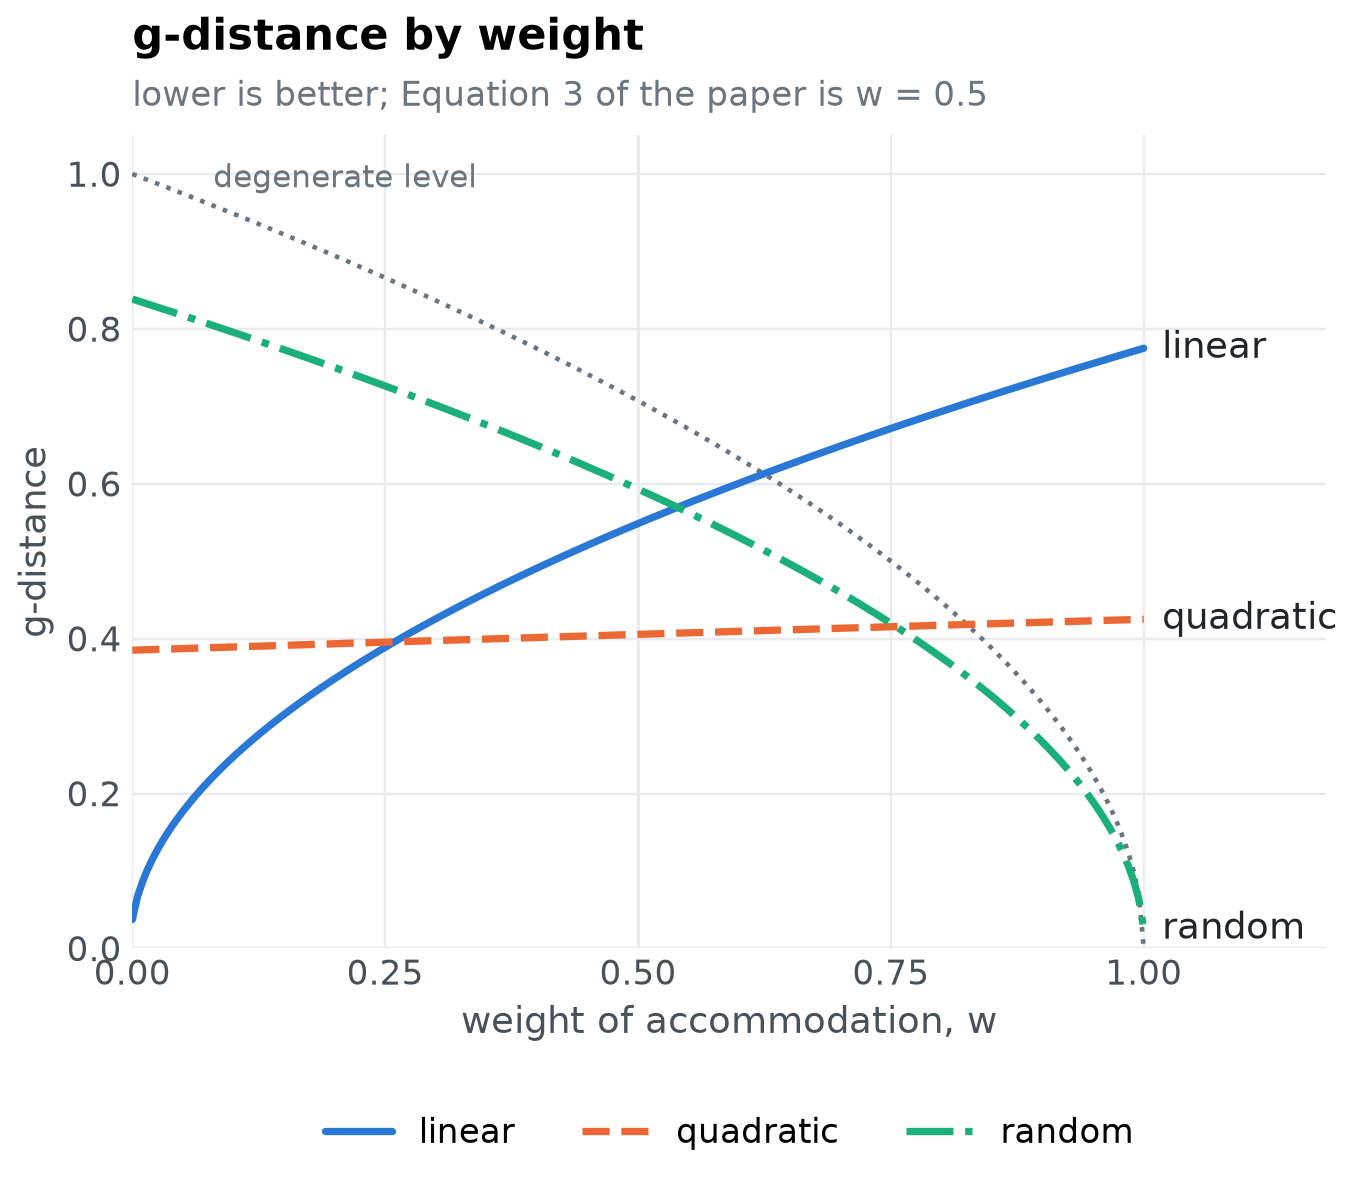

The model closest to the ideal is the **linear** model for w from 0.00 to 0.26, the **quadratic** model for w from 0.26 to 0.76, the **random** model for w from 0.76 to 1.00. Where the verdict depends on the weight, it is worth stating the range of weights one finds plausible, rather than a single value (Dome & Wills, 2025).

In [8]:
weights = np.linspace(0, 1, 201)
curves = {name: np.sqrt(weights * (1 - row.alpha) ** 2 + (1 - weights) * row.beta**2)
          for name, row in scores.iterrows()}
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(weights, np.sqrt(1 - weights), ":", color=muted, linewidth=1.5)
ax.annotate("degenerate level", (0.08, math.sqrt(1 - 0.08)), xytext=(0, 6), textcoords="offset points",
            color=muted, fontsize=10)
for name, g in curves.items():
    ax.plot(weights, g, color=colours[name], linestyle=styles[name], linewidth=2.4, label=name)
    ax.annotate(name, (1, g[-1]), xytext=(6, 0), textcoords="offset points", color=ink, va="center")
ax.axvline(0.5, color=light, linewidth=1, zorder=0)
ax.set(xlim=(0, 1.18), ylim=(0, 1.05), xticks=[0, 0.25, 0.5, 0.75, 1],
       xlabel="weight of accommodation, w", ylabel="g-distance")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
titled(ax, "g-distance by weight", "lower is better; Equation 3 of the paper is w = 0.5")
show(fig, "by-weight")

best = pd.Series([min(curves, key=lambda n: curves[n][i]) for i in range(len(weights))], index=weights)
spans = []
for name, group in best.groupby((best != best.shift()).cumsum()):
    spans.append(f"the **{group.iloc[0]}** model for w from {group.index[0]:.2f} to {group.index[-1]:.2f}")
display(Markdown("The model closest to the ideal is " + ", ".join(spans) + ". Where the verdict "
                 "depends on the weight, it is worth stating the range of weights one finds plausible, "
                 "rather than a single value (Dome & Wills, 2025)."))

## Things to know

- **Patterns are counted once.** If the model produces a pattern at many parameter settings, it still counts once in $M$. The same holds for $H$ in $\beta$.
- **Give each human pattern once, with frequencies that sum to 1.** `frequencies` must have exactly one value per matrix in `human`, or `gdistance()` raises an error. $\alpha$ adds up the frequency of every accommodated matrix, so a pattern that appears twice in `human` would be counted twice. `gdistance()` warns if `human` repeats a pattern or if the frequencies do not sum to 1 (for example, because they are counts rather than proportions). `patterns()` returns the distinct patterns with frequencies that sum to 1, so its output can be passed straight in.
- **Only the upper triangle matters.** Two matrices are the same pattern if their cells above the diagonal agree. Those cells can hold any numbers, so you can code relations your own way, but not missing values: NaN is not equal to anything, not even another NaN, so `gdistance()` rejects it.
- **When people show every possible pattern**, $|U| - |H| = 0$ and $\beta$ cannot be computed. `gdistance()` then warns, sets `beta` to NaN and uses accommodation alone.
- **The universal set must match how patterns were built**: the same thresholds, the same `ordering`, and a measurement scale that can produce them. [universal-set.ipynb](universal-set.ipynb) explains how to get it right.
- **The model's patterns can come from a parameter space partitioning run**: `gdistance()` takes `PSPResult.ordinal_patterns` as it is (see the end of [getting-started.ipynb](getting-started.ipynb)).

## Near misses

$\alpha$ treats a missed pattern as missed, however close the model came. `pattern_distance()` tells you how close that was. Its default adds up the differences between the two patterns, pair by pair:

$$
d(a, b) = \sum_{i < j} |a_{ij} - b_{ij}|.
$$

With the usual coding of 1, 0 and -1, this is the distance between rankings of Kemeny and Snell (1962), applied to inequality matrices (see the appendix): it adds 1 for every pair of stimuli that is ordered in one pattern and about the same in the other, and 2 for every pair whose order is reversed. If you code relations in more levels, for example -2 (much smaller) to 2 (much larger), it adds the number of levels between the two relations. If your codes are just labels without an order, use `method="hamming"`, which counts the pairs that differ.

In the worked example, the model missed pattern C (all three stimuli about the same). How close did it get?

In [9]:
human = clobe.patterns(people, thresholds)
model = clobe.patterns(torch.tensor([[0.9, 0.5, 0.1], [0.1, 0.5, 0.9],
                                     [0.9, 0.9, 0.1], [0.1, 0.9, 0.9]]), thresholds)
distances = clobe.pattern_distance(human.inequality_matrices, model.inequality_matrices)
distances, distances.min(dim=1).values

(tensor([[0., 6., 1., 5.],
         [6., 0., 5., 1.],
         [3., 3., 2., 2.]], dtype=torch.float64),
 tensor([0., 0., 2.], dtype=torch.float64))

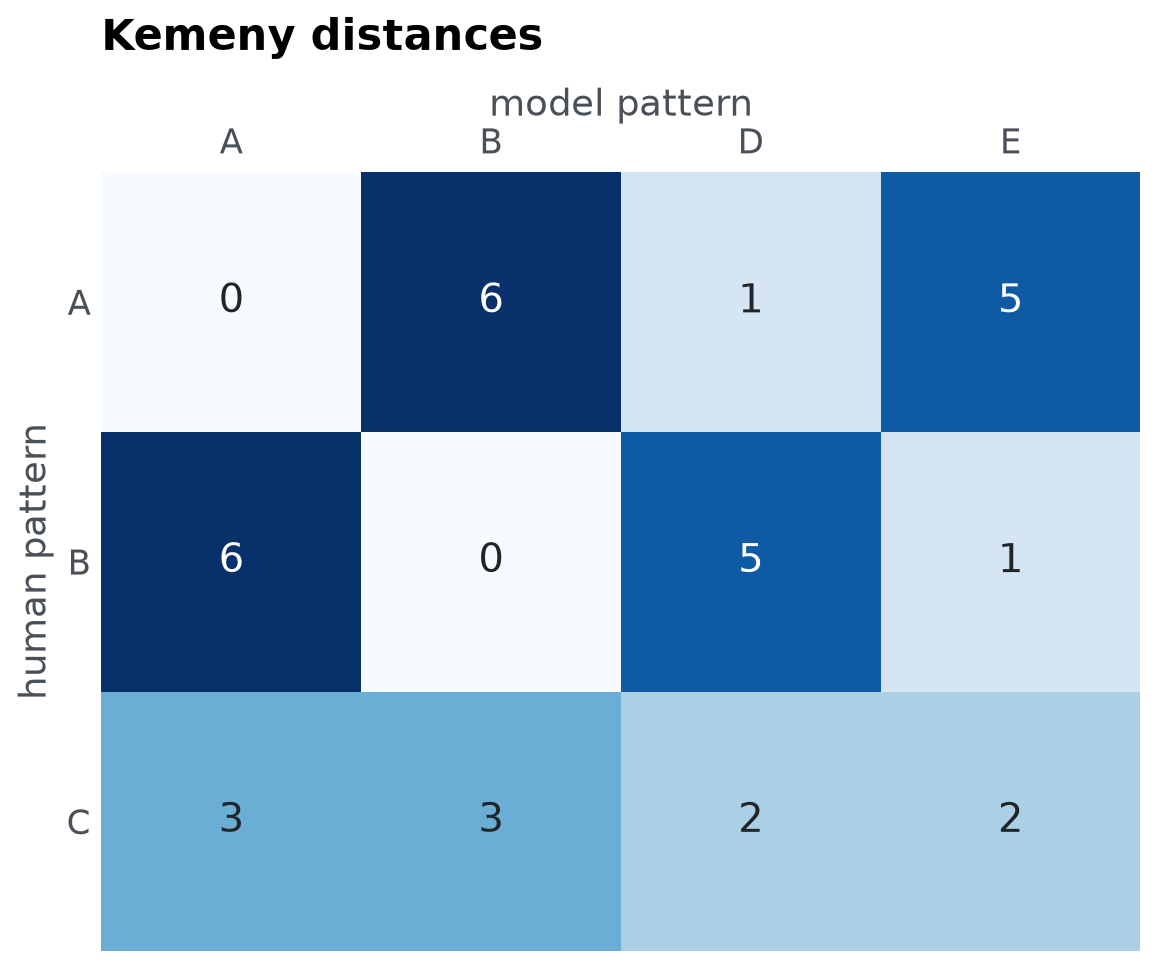

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.imshow(distances.numpy(), cmap="Blues", vmin=0, vmax=6)
for (r, c), d in np.ndenumerate(distances.numpy()):
    ax.text(c, r, f"{d:g}", ha="center", va="center", fontsize=13,
            color="white" if d >= 4 else ink)
ax.set(xticks=range(4), xticklabels=["A", "B", "D", "E"], yticks=range(3), yticklabels=["A", "B", "C"],
       xlabel="model pattern", ylabel="human pattern")
ax.grid(False)
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()
ax.set_title("Kemeny distances", pad=40)
show(fig, "near-misses")

Each row is a human pattern and each column a model pattern. A and B are matched exactly (distance 0). The closest the model comes to C is a distance of 2: patterns D and E each tie two of the stimuli, as C does, but separate the third.

## Appendix: the Kemeny-Snell distance

Kemeny and Snell (1962) asked what a distance between two rankings should satisfy, set out four axioms (the properties of a metric, invariance to relabelling the objects, consistency when two rankings differ only on a segment, and a minimum positive distance of 1), and showed that exactly one distance satisfies them all. Written with the score matrices of the rankings, where $a_{ij}$ is $1$, $-1$ or $0$ as object $i$ is ranked above, below or tied with object $j$, it is

$$
d(A, B) = \frac{1}{2} \sum_{i=1}^{m} \sum_{j=1}^{m} \left| a_{ij} - b_{ij} \right|
$$

(Amodio, D'Ambrosio & Siciliano, 2016, Equation 4). A score matrix is antisymmetric, $a_{ji} = -a_{ij}$, so the cells below the diagonal repeat those above, and the half of the double sum is the sum over the cells above the diagonal: what `pattern_distance()` computes from inequality matrices. Kemeny and Snell defined the distance for rankings, which are weak orderings; applying it to semiorders that are not weak orderings is an extension made by clobe.

## References

Amodio, S., D'Ambrosio, A., & Siciliano, R. (2016). Accurate algorithms for identifying the median ranking when dealing with weak and partial rankings under the Kemeny axiomatic approach. *European Journal of Operational Research, 249*(2), 667-676. https://doi.org/10.1016/j.ejor.2015.08.048

Dome, L., & Wills, A. J. (2025). g-Distance: On the comparison of model and human heterogeneity. *Psychological Review, 132*(3), 632-655. https://doi.org/10.1037/rev0000550

Kemeny, J. G., & Snell, J. L. (1962). *Mathematical models in the social sciences*. Ginn.